In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import SelectKBest, f_classif

In [2]:
#Load data
#Data = pd.read_csv('/Users/blessingodeleye/Documents/VR_data/Labelled_data_set.csv')
Data =  pd.read_csv('/Users/blessingodeleye/Documents/VR_data2/Data.csv')

In [3]:
Data = Data.iloc[:, 1:]

In [4]:
Data

,FPS,Frame Duration (ms),Min Frame Duration (ms),Max Frame Duration (ms),Avg Frame Duration (ms),Std Dev (ms),Entropy Framerate,MotionToPhotonLatency,minMtpLatency,maxMtpLatency,avgMtpLatency,StdDev mtpLatency,mtpEntropy,currentRotation.x,currentRotation.y,currentRotation.z,currentRotation.w,pitch,yaw,roll
0,62.06,16.11,0.00,16.11,16.11,16.11,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.34,-0.10,-0.14,0.92,37.27,339.66,335.71
1,68.85,14.52,0.00,16.11,14.92,10.58,0.00,14.52,0.00,14.52,10.89,7.26,0.00,0.34,-0.10,-0.14,0.92,37.13,339.59,335.73
2,76.57,13.06,0.00,16.11,13.61,8.01,0.00,14.52,14.52,14.52,10.89,6.85,0.00,0.34,-0.10,-0.14,0.92,36.98,339.55,335.75
3,79.07,12.65,0.00,16.11,12.95,6.71,0.00,25.71,14.52,25.71,21.02,9.13,0.74,0.34,-0.10,-0.14,0.92,36.87,339.55,335.85
4,69.74,14.34,0.00,16.11,13.88,6.33,0.21,14.34,14.34,25.71,16.53,8.17,0.51,0.34,-0.10,-0.14,0.93,36.70,339.47,336.03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10327,36.55,27.36,27.36,115.83,67.79,26.53,1.09,27.34,27.34,115.84,69.43,30.18,1.34,0.34,-0.41,0.13,0.84,42.33,305.84,354.87
10328,10.96,91.25,27.36,115.83,67.82,30.96,1.28,91.25,27.34,91.25,69.45,30.29,0.89,0.34,-0.41,0.12,0.84,42.55,305.32,354.15
10329,11.73,85.22,27.36,115.83,67.83,30.43,0.84,85.24,85.24,91.25,69.47,29.81,0.00,0.35,-0.41,0.14,0.83,44.41,306.12,355.37
10330,23.38,42.78,27.36,115.83,67.81,31.04,0.63,42.76,42.76,85.24,69.44,32.61,0.96,0.36,-0.40,0.14,0.83,45.45,306.43,355.80


In [5]:
# create new column "Labels" based on "FPS"
Data["Labels"] = Data["FPS"].apply(lambda x: 0 if x >= 60 else 1)

In [6]:
Data.shape

(10332, 21)

In [7]:
X = Data.iloc[:, 0 :]
X.drop('Labels', axis=1, inplace=True)

In [8]:
y = Data['Labels']

In [9]:
# Use SelectKBest with f_classif as the scoring function
k = 5
skb = SelectKBest(f_classif, k=k)
X_skb = skb.fit_transform(X, y)

In [10]:
# Print the selected features
selected_features = X.columns[skb.get_support()]
print("Selected Features:", selected_features)

Selected Features: Index(['FPS', 'Min Frame Duration (ms)', 'Max Frame Duration (ms)',
       'Avg Frame Duration (ms)', 'avgMtpLatency'],
      dtype='object')


In [11]:
# Calculate F-scores and p-values from SelectKBest
f_scores = skb.scores_[skb.get_support()]
p_values = skb.pvalues_[skb.get_support()]

In [12]:
# Sort the features and their F-scores and p-values from most to least important
sorted_indices = np.argsort(f_scores)[::-1]
sorted_features = selected_features[sorted_indices]
sorted_f_scores = f_scores[sorted_indices]
sorted_p_values = p_values[sorted_indices]

In [17]:
# Print sorted F-scores and p-values
print("\nSorted F-scores:")
for feature, f_score in zip(sorted_features, sorted_f_scores):
    print(f"{feature}: {f_score}")

print("\nSorted p-values:")
for feature, p_value in zip(sorted_features, sorted_p_values):
    print(f"{feature}: {p_value}")


Sorted F-scores:
FPS: 46521.5472173188
avgMtpLatency: 13343.876382981936
Avg Frame Duration (ms): 12685.06620128682
Min Frame Duration (ms): 3025.6817325261686
Max Frame Duration (ms): 2486.711829468978

Sorted p-values:
FPS: 0.0
avgMtpLatency: 0.0
Avg Frame Duration (ms): 0.0
Min Frame Duration (ms): 0.0
Max Frame Duration (ms): 0.0


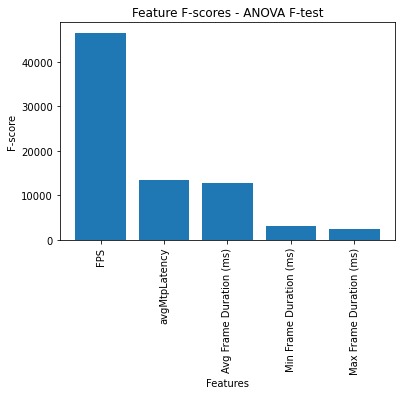

In [14]:
# Plot a bar chart of the sorted F-scores
plt.bar(sorted_features, sorted_f_scores)
plt.title("Feature F-scores - ANOVA F-test")
plt.xlabel("Features")
plt.ylabel("F-score")
plt.xticks(rotation=90)
plt.show()